# zappend Demo

This Notebook demonstrates the two user interfaces of the `zappend` tool, namely the CLI and API with some local NetCDF inputs.

In [1]:
import glob
import os
import os.path
import shutil
from pathlib import Path

import xarray as xr

First let's define a utility to remove directories:

In [2]:
def rmdir(path: str):
    if os.path.exists(path):
        shutil.rmtree(path)

## Define the inputs

We use Ocean Colour data produced by the [EU HIGHROC Project](https://www.highroc.eu/) as input.

In [3]:
slice_pattern = "inputs/demo/*.nc"

In [4]:
slice_paths = sorted(glob.glob(slice_pattern))[:3]
slice_paths

['inputs/demo/20230601_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc',
 'inputs/demo/20230603_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc',
 'inputs/demo/20230605_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc']

This is how a single slice looks like:

In [5]:
slice_ds = xr.open_dataset(slice_paths[0])
slice_ds

<xarray.Dataset> Size: 475MB
Dimensions:  (time: 1, lat: 8640, lon: 3435)
Coordinates:
  * time     (time) datetime64[ns] 8B 2023-06-01
  * lat      (lat) float64 69kB 64.0 64.0 64.0 64.0 64.0 ... 56.0 56.0 56.0 56.0
  * lon      (lon) float64 27kB 6.0 6.002 6.004 6.005 ... 11.99 12.0 12.0 12.0
Data variables:
    SPM      (time, lat, lon) float32 119MB ...
    TUR      (time, lat, lon) float32 119MB ...
    SPM_QI   (time, lat, lon) float32 119MB ...
    TUR_QI   (time, lat, lon) float32 119MB ...
    crs      int32 4B ...
Attributes: (12/46)
    TileSize:                   540:286
    id:                         20230601_P1D_CMEMS_HROC_L3_transp_BAL_32V_100...
    title:                      CMEMS HR-OC Baltic Sea transparency (spm, tur...
    region:                     BAL
    tile:                       32V
    cmems_product_id:           OCEANCOLOUR_BAL_BGC_HR_L3_NRT_009_202
    ...                         ...
    time_coverage_duration:     P1D
    time_coverage_resolution:   P1D
    platform:                   Sentinel-2
    sensor:                     MSI
    start_date:                 01-JUN-2023 00:00:00.000000
    stop_date:                  01-JUN-2023 00:00:00.000000

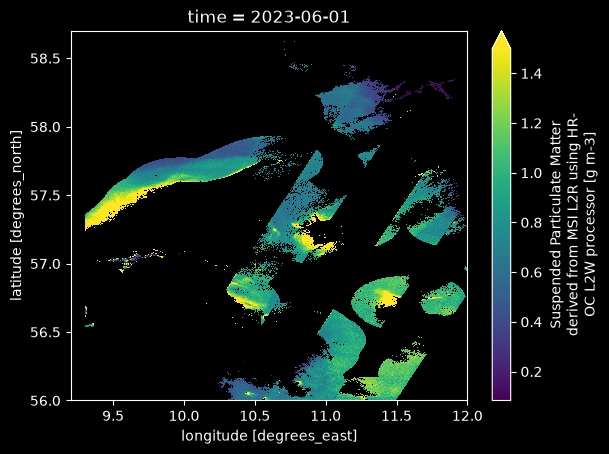

In [6]:
slice_ds.SPM.isel(time=0).sel(lon=slice(9.2, 12), lat=slice(58.7, 56)).plot.imshow(
    vmax=1.5
)

## Define the output

In [7]:
output_dir = Path("outputs")
output_dir.mkdir(exist_ok=True)
target_path = f"{output_dir}/target.zarr"

In [8]:
rmdir(target_path)

## Use the zappend CLI

In [9]:
!zappend --help

Usage: zappend [OPTIONS] [SLICES]...

  Create or update a Zarr datacube TARGET from slice datasets SLICES.

  The zappend command concatenates the dataset SLICES along a given append
  dimension, e.g., "time" (the default) for geospatial satellite observations.
  Each append step is atomic, that is, the append operation is a transaction
  that can be rolled back, in case the append operation fails. This ensures
  integrity of the target data cube given by TARGET or in CONFIG.

Options:
  -c, --config CONFIG    Configuration JSON or YAML file. If multiple are
                         passed, subsequent configurations are incremental to
                         the previous ones.
  -t, --target TARGET    Target Zarr dataset path or URI. Overrides the
                         'target_dir' configuration field.
  --force-new            Force creation of a new target dataset. An existing
                         target dataset (and its lock) will be permanently
                         dele

In [10]:
!zappend --version

0.8.1.dev0


Run the tool without any additional configuration:

In [11]:
!zappend -t {target_path} {" ".join(slice_paths)}

3 slice datasets processed.


Check the target dataset just generated:

In [12]:
target_ds = xr.open_zarr(target_path)
target_ds

<xarray.Dataset> Size: 1GB
Dimensions:  (time: 3, lat: 8640, lon: 3435)
Coordinates:
  * time     (time) datetime64[ns] 24B 2023-06-01 2023-06-03 2023-06-05
  * lat      (lat) float64 69kB 64.0 64.0 64.0 64.0 64.0 ... 56.0 56.0 56.0 56.0
  * lon      (lon) float64 27kB 6.0 6.002 6.004 6.005 ... 11.99 12.0 12.0 12.0
Data variables:
    crs      int32 4B ...
    SPM      (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
    SPM_QI   (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
    TUR      (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
    TUR_QI   (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
Attributes: (12/46)
    TileSize:                   540:286
    id:                         20230601_P1D_CMEMS_HROC_L3_transp_BAL_32V_100...
    title:                      CMEMS HR-OC Baltic Sea transparency (spm, tur...
    region:                     BAL
    tile:                       32V
    cmems_product_id:           OCEANCOLOUR_BAL_BGC_HR_L3_NRT_009_202
    ...                         ...
    time_coverage_duration:     P1D
    time_coverage_resolution:   P1D
    platform:                   Sentinel-2
    sensor:                     MSI
    start_date:                 01-JUN-2023 00:00:00.000000
    stop_date:                  01-JUN-2023 00:00:00.000000

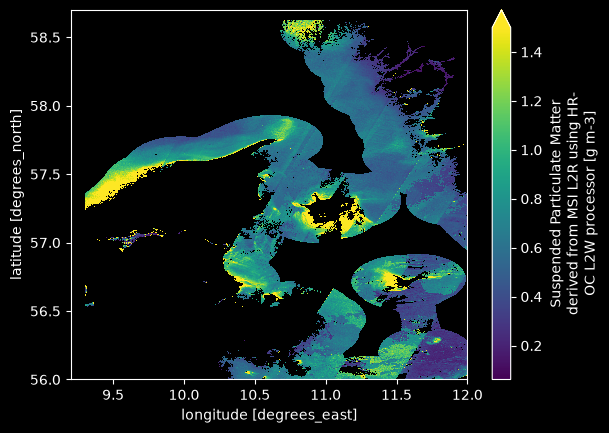

In [13]:
target_ds.SPM.mean("time").sel(lon=slice(9.2, 12), lat=slice(58.7, 56)).plot.imshow(
    vmax=1.5
)

/home/konstantin/micromamba/envs/zappend/lib/python3.15/site-packages/dask/array/reductions.py:327: RuntimeWarning: All-NaN slice encountered
  return np.nanmax(x_chunk, axis=axis, keepdims=keepdims)


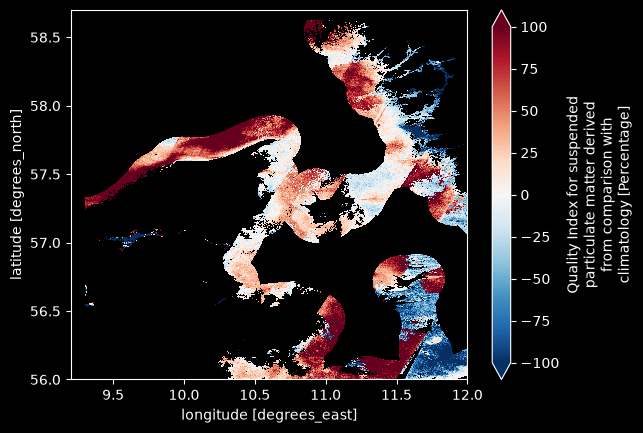

In [14]:
target_ds.SPM_QI.max("time").sel(lon=slice(9.2, 12), lat=slice(58.7, 56)).plot.imshow(
    vmax=100.0
)

## Use the zappend API

Now the same using the API:

In [15]:
from zappend.api import zappend

In [16]:
help(zappend)

Help on function zappend in module zappend.api:

zappend(slices: Iterable[Any], config: ConfigLike = None, **kwargs: Any) -> int
    Robustly create or update a Zarr dataset from dataset slices.

    The `zappend` function concatenates the dataset slices from given
    `slices` along a given append dimension, e.g., `"time"` (the default)
    for geospatial satellite observations.
    Each append step is atomic, that is, the append operation is a transaction
    that can be rolled back, in case the append operation fails.
    This ensures integrity of the  target data cube `target_dir` given
    in `config` or `kwargs`.

    Each slice item in `slices` provides a slice dataset to be appended.
    The interpretation of a given slice item depends on whether a slice source
    is configured or not (setting `slice_source`).

    If no slice source is configured, a slice item must be an object of type
    `str`, `FileObj`, `xarray.Dataset`, or `SliceSource`.
    If `str` or `FileObj` are use

In [17]:
# Remove existing target datacube
rmdir(target_path)

Run the tool without any additional configuration:

In [18]:
zappend(slice_paths, target_dir=target_path)

3

Check the target dataset just generated:

In [19]:
xr.open_zarr(target_path)

<xarray.Dataset> Size: 1GB
Dimensions:  (time: 3, lat: 8640, lon: 3435)
Coordinates:
  * time     (time) datetime64[ns] 24B 2023-06-01 2023-06-03 2023-06-05
  * lat      (lat) float64 69kB 64.0 64.0 64.0 64.0 64.0 ... 56.0 56.0 56.0 56.0
  * lon      (lon) float64 27kB 6.0 6.002 6.004 6.005 ... 11.99 12.0 12.0 12.0
Data variables:
    crs      int32 4B ...
    SPM      (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
    SPM_QI   (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
    TUR      (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
    TUR_QI   (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
Attributes: (12/46)
    TileSize:                   540:286
    id:                         20230601_P1D_CMEMS_HROC_L3_transp_BAL_32V_100...
    title:                      CMEMS HR-OC Baltic Sea transparency (spm, tur...
    region:                     BAL
    tile:                       32V
    cmems_product_id:           OCEANCOLOUR_BAL_BGC_HR_L3_NRT_009_202
    ...                         ...
    time_coverage_duration:     P1D
    time_coverage_resolution:   P1D
    platform:                   Sentinel-2
    sensor:                     MSI
    start_date:                 01-JUN-2023 00:00:00.000000
    stop_date:                  01-JUN-2023 00:00:00.000000

Check that time is monotonically increasing:

## zappend Configuration

Now we'll add some configuration. 
You can run `zappend --help-config md` to get configuration help, or do that programmatically:

In [20]:
# Uncomment to show configuration reference
# Markdown(get_config_schema(format="md"))

In [21]:
config = {
    "target_dir": target_path,
    "variables": {
        # We want the time coordinate variable to use a larger chunk size
        # than the default (= 1 here)
        "time": {"encoding": {"chunks": [100]}}
    },
    # Log to the console.
    # Note you could also configure the log output for dask here.
    "logging": {
        "version": 1,
        "formatters": {
            "normal": {"format": "%(asctime)s %(levelname)s %(message)s", "style": "%"}
        },
        "handlers": {
            "console": {"class": "logging.StreamHandler", "formatter": "normal"}
        },
        "loggers": {
            "zappend": {"level": "INFO", "handlers": ["console"]},
            "notebook": {
                # Will use this one later below
                "level": "INFO",
                "handlers": ["console"],
            },
        },
    },
}

In [22]:
config_path = "zappend-config.yaml"

In [23]:
import yaml

with open(config_path, mode="w") as f:
    yaml.dump(config, f)

## zappend CLI with Configuration

In [24]:
rmdir(target_path)

In [25]:
!zappend -c {config_path} {" ".join(slice_paths)}

2026-10-29 17:41:12,507 INFO Opening slice dataset from inputs/demo/20230601_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:12,537 INFO Creating target dataset outputs/target.zarr
2026-10-29 17:41:14,649 INFO Transaction completed.
2026-10-29 17:41:14,667 INFO Slice dataset inputs/demo/20230601_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc closed
2026-10-29 17:41:14,676 INFO Opening slice dataset from inputs/demo/20230603_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:14,689 INFO Updating target dataset outputs/target.zarr
2026-10-29 17:41:16,816 INFO Transaction completed.
2026-10-29 17:41:16,833 INFO Slice dataset inputs/demo/20230603_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc closed
2026-10-29 17:41:16,843 INFO Opening slice dataset from inputs/demo/20230605_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:16,851 INFO Updating target dataset outputs/target.zarr
2026-10-29 17:41:18,822 INFO Transaction completed.
2026-10-29 17:41:

In [26]:
rmdir(target_path)

## zappend API with Configuration

In [27]:
from zappend.api import zappend

The `zappend` function can process slice paths or URIs, e.g., `s3://...` or slice datasets of type `xr.Dataset`:

In [28]:
zappend(slice_paths, config=config)

2026-10-29 17:41:19,277 INFO Opening slice dataset from inputs/demo/20230601_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:19,292 INFO Creating target dataset outputs/target.zarr
2026-10-29 17:41:21,157 INFO Transaction completed.
2026-10-29 17:41:21,158 INFO Slice dataset inputs/demo/20230601_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc closed
2026-10-29 17:41:21,169 INFO Opening slice dataset from inputs/demo/20230603_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:21,179 INFO Updating target dataset outputs/target.zarr
2026-10-29 17:41:23,340 INFO Transaction completed.
2026-10-29 17:41:23,341 INFO Slice dataset inputs/demo/20230603_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc closed
2026-10-29 17:41:23,352 INFO Opening slice dataset from inputs/demo/20230605_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:23,361 INFO Updating target dataset outputs/target.zarr
2026-10-29 17:41:25,290 INFO Transaction completed.
2026-10-29 17:41:

3

In [29]:
xr.open_zarr(target_path)

<xarray.Dataset> Size: 1GB
Dimensions:  (time: 3, lat: 8640, lon: 3435)
Coordinates:
  * time     (time) datetime64[ns] 24B 2023-06-01 2023-06-03 2023-06-05
  * lat      (lat) float64 69kB 64.0 64.0 64.0 64.0 64.0 ... 56.0 56.0 56.0 56.0
  * lon      (lon) float64 27kB 6.0 6.002 6.004 6.005 ... 11.99 12.0 12.0 12.0
Data variables:
    crs      int32 4B ...
    SPM      (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
    SPM_QI   (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
    TUR      (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
    TUR_QI   (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
Attributes: (12/46)
    TileSize:                   540:286
    id:                         20230601_P1D_CMEMS_HROC_L3_transp_BAL_32V_100...
    title:                      CMEMS HR-OC Baltic Sea transparency (spm, tur...
    region:                     BAL
    tile:                       32V
    cmems_product_id:           OCEANCOLOUR_BAL_BGC_HR_L3_NRT_009_202
    ...                         ...
    time_coverage_duration:     P1D
    time_coverage_resolution:   P1D
    platform:                   Sentinel-2
    sensor:                     MSI
    start_date:                 01-JUN-2023 00:00:00.000000
    stop_date:                  01-JUN-2023 00:00:00.000000

## Other slice types

In [30]:
rmdir(target_path)

Get the configured logger: 

In [31]:
from logging import getLogger

LOG = getLogger("notebook")

The `zappend` function can also process in-memory slice datasets of type `xr.Dataset`:

In [32]:
log = getLogger("notebook")


def process_slice(slice_path: str) -> xr.Dataset:
    LOG.info(f"Processing slice {slice_path}")
    slice_ds = xr.open_dataset(slice_path)
    return slice_ds.drop_vars(["SPM_QI", "TUR_QI", "crs"])


slice_generator = (process_slice(slice_path) for slice_path in slice_paths)

In [33]:
zappend(slice_generator, config=config)

2026-10-29 17:41:25,431 INFO Processing slice inputs/demo/20230601_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:25,443 INFO Processing in-memory slice dataset #0
2026-10-29 17:41:25,445 INFO Creating target dataset outputs/target.zarr
2026-10-29 17:41:26,531 INFO Transaction completed.
2026-10-29 17:41:26,531 INFO Slice dataset #0 processed
2026-10-29 17:41:26,532 INFO Processing slice inputs/demo/20230603_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:26,550 INFO Processing in-memory slice dataset #1
2026-10-29 17:41:26,551 INFO Updating target dataset outputs/target.zarr
2026-10-29 17:41:27,536 INFO Transaction completed.
2026-10-29 17:41:27,537 INFO Slice dataset #1 processed
2026-10-29 17:41:27,537 INFO Processing slice inputs/demo/20230605_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:27,566 INFO Processing in-memory slice dataset #2
2026-10-29 17:41:27,568 INFO Updating target dataset outputs/target.zarr
2026-10-29 17:41:28,66

3

In [34]:
xr.open_zarr(target_path)

<xarray.Dataset> Size: 712MB
Dimensions:  (time: 3, lat: 8640, lon: 3435)
Coordinates:
  * time     (time) datetime64[ns] 24B 2023-06-01 2023-06-03 2023-06-05
  * lat      (lat) float64 69kB 64.0 64.0 64.0 64.0 64.0 ... 56.0 56.0 56.0 56.0
  * lon      (lon) float64 27kB 6.0 6.002 6.004 6.005 ... 11.99 12.0 12.0 12.0
Data variables:
    SPM      (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
    TUR      (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
Attributes: (12/46)
    TileSize:                   540:286
    id:                         20230601_P1D_CMEMS_HROC_L3_transp_BAL_32V_100...
    title:                      CMEMS HR-OC Baltic Sea transparency (spm, tur...
    region:                     BAL
    tile:                       32V
    cmems_product_id:           OCEANCOLOUR_BAL_BGC_HR_L3_NRT_009_202
    ...                         ...
    time_coverage_duration:     P1D
    time_coverage_resolution:   P1D
    platform:                   Sentinel-2
    sensor:                     MSI
    start_date:                 01-JUN-2023 00:00:00.000000
    stop_date:                  01-JUN-2023 00:00:00.000000

In the case that you need make sure the dataset is really closed after slice processing 
or in order to clean up temporary resource you can write a `SliceSource`:

In [35]:
rmdir(target_path)

In [36]:
from zappend.api import SliceSource


class MySliceSource(SliceSource):
    def __init__(self, slice_path):
        self.slice_path = slice_path
        self.slice_ds = None

    def get_dataset(self) -> xr.Dataset:
        LOG.info(f"Processing slice {self.slice_path}")
        self.slice_ds = xr.open_dataset(self.slice_path)
        return self.slice_ds.drop_vars(["SPM_QI", "TUR_QI", "crs"])

    def dispose(self):
        self.slice_ds.close()
        self.slice_ds = None
        LOG.info("Slice processed")

In [37]:
zappend(slice_paths, config=config, slice_source=MySliceSource)

2026-10-29 17:41:28,767 INFO Processing slice inputs/demo/20230601_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:28,777 INFO Creating target dataset outputs/target.zarr
2026-10-29 17:41:29,802 INFO Transaction completed.
2026-10-29 17:41:29,802 INFO Slice processed
2026-10-29 17:41:29,812 INFO Processing slice inputs/demo/20230603_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:29,821 INFO Updating target dataset outputs/target.zarr
2026-10-29 17:41:30,794 INFO Transaction completed.
2026-10-29 17:41:30,796 INFO Slice processed
2026-10-29 17:41:30,806 INFO Processing slice inputs/demo/20230605_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:30,814 INFO Updating target dataset outputs/target.zarr
2026-10-29 17:41:32,907 INFO Transaction completed.
2026-10-29 17:41:32,910 INFO Slice processed


3

In [38]:
xr.open_zarr(target_path)

<xarray.Dataset> Size: 712MB
Dimensions:  (time: 3, lat: 8640, lon: 3435)
Coordinates:
  * time     (time) datetime64[ns] 24B 2023-06-01 2023-06-03 2023-06-05
  * lat      (lat) float64 69kB 64.0 64.0 64.0 64.0 64.0 ... 56.0 56.0 56.0 56.0
  * lon      (lon) float64 27kB 6.0 6.002 6.004 6.005 ... 11.99 12.0 12.0 12.0
Data variables:
    SPM      (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
    TUR      (time, lat, lon) float32 356MB dask.array<chunksize=(1, 540, 286), meta=np.ndarray>
Attributes: (12/46)
    TileSize:                   540:286
    id:                         20230601_P1D_CMEMS_HROC_L3_transp_BAL_32V_100...
    title:                      CMEMS HR-OC Baltic Sea transparency (spm, tur...
    region:                     BAL
    tile:                       32V
    cmems_product_id:           OCEANCOLOUR_BAL_BGC_HR_L3_NRT_009_202
    ...                         ...
    time_coverage_duration:     P1D
    time_coverage_resolution:   P1D
    platform:                   Sentinel-2
    sensor:                     MSI
    start_date:                 01-JUN-2023 00:00:00.000000
    stop_date:                  01-JUN-2023 00:00:00.000000

## Enforce Transaction Rollback

Demonstrate that appending a slice is a transaction, that is rolled back on error.

To simulate a failure that occurs on a random data chunk, we define the following 
slice source `MyGrottySliceSource` that will fail when computing the 12th 
chunk of a newly computed (useless) variable `SPM_05`.

In [39]:
from zappend.api import SliceSource


class MyGrottySliceSource(SliceSource):
    def __init__(self, slice_path):
        self.slice_path = slice_path
        self.slice_ds = None
        self.is_bad = "20230605" in slice_path
        self.num_chunks_seen = 0

    def half_spm(self, spm):
        if self.is_bad:
            self.num_chunks_seen += 1
            if self.num_chunks_seen == 12:
                raise ValueError("Bad chunk detected!")
        return 0.5 * spm

    def get_dataset(self) -> xr.Dataset:
        LOG.info(f"Processing slice {self.slice_path}")
        slice_ds = xr.open_dataset(self.slice_path)
        slice_ds = slice_ds.drop_vars(["SPM_QI", "TUR_QI", "crs"])
        slice_ds = slice_ds.chunk({"lon": 2000, "lat": 1000})
        for v in slice_ds.data_vars.values():
            v.encoding = {}
        slice_ds["SPM_05"] = slice_ds["SPM"].map_blocks(
            self.half_spm, template=slice_ds["SPM"]
        )
        self.slice_ds = slice_ds
        return slice_ds

    def dispose(self):
        self.slice_ds.close()
        self.slice_ds = None
        LOG.info("Slice processed")

The following `zappend` call will fail on third slice, but changes will be rolled back so that 
the target dataset is still ok, rather than in an invalid state.

In [40]:
rmdir(target_path)

In [41]:
rmdir(target_path)
zappend(slice_paths, target_dir=target_path, slice_source=MyGrottySliceSource)

2026-10-29 17:41:33,090 INFO Processing slice inputs/demo/20230601_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:33,126 INFO Creating target dataset outputs/target.zarr
2026-10-29 17:41:34,465 INFO Transaction completed.
2026-10-29 17:41:34,466 INFO Slice processed
2026-10-29 17:41:34,490 INFO Processing slice inputs/demo/20230603_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:34,519 INFO Updating target dataset outputs/target.zarr
2026-10-29 17:41:35,929 INFO Transaction completed.
2026-10-29 17:41:35,930 INFO Slice processed
2026-10-29 17:41:35,949 INFO Processing slice inputs/demo/20230605_P1D_CMEMS_HROC_L3-transp_BAL_32V_100m-v01.4.nc
2026-10-29 17:41:35,972 INFO Updating target dataset outputs/target.zarr
2026-10-29 17:41:36,426 ERROR Error in transaction
Traceback (most recent call last):
  File "/home/konstantin/micromamba/envs/zappend/lib/python3.15/site-packages/zappend/processor.py", line 122, in process_slice
    update_target_from_slice(ct

ValueError: Bad chunk detected!

Verify that the target dataset can be opened but has only two of three time steps:

In [42]:
xr.open_zarr(target_path)

<xarray.Dataset> Size: 712MB
Dimensions:  (time: 2, lat: 8640, lon: 3435)
Coordinates:
  * time     (time) datetime64[ns] 16B 2023-06-01 2023-06-03
  * lat      (lat) float64 69kB 64.0 64.0 64.0 64.0 64.0 ... 56.0 56.0 56.0 56.0
  * lon      (lon) float64 27kB 6.0 6.002 6.004 6.005 ... 11.99 12.0 12.0 12.0
Data variables:
    SPM      (time, lat, lon) float32 237MB dask.array<chunksize=(1, 1000, 2000), meta=np.ndarray>
    SPM_05   (time, lat, lon) float32 237MB dask.array<chunksize=(1, 1000, 2000), meta=np.ndarray>
    TUR      (time, lat, lon) float32 237MB dask.array<chunksize=(1, 1000, 2000), meta=np.ndarray>
Attributes: (12/46)
    TileSize:                   540:286
    id:                         20230601_P1D_CMEMS_HROC_L3_transp_BAL_32V_100...
    title:                      CMEMS HR-OC Baltic Sea transparency (spm, tur...
    region:                     BAL
    tile:                       32V
    cmems_product_id:           OCEANCOLOUR_BAL_BGC_HR_L3_NRT_009_202
    ...                         ...
    time_coverage_duration:     P1D
    time_coverage_resolution:   P1D
    platform:                   Sentinel-2
    sensor:                     MSI
    start_date:                 01-JUN-2023 00:00:00.000000
    stop_date:                  01-JUN-2023 00:00:00.000000

---

In [43]:
rmdir(target_path)